In [1]:
#Neural network classification using Pytorch

In [2]:
#Data

In [3]:
import sklearn
from sklearn.datasets import make_circles

In [4]:
n_samples=1000

In [5]:
x,y=make_circles(n_samples,noise=0.03,random_state=42)

In [6]:
x[:5]

array([[ 0.75424625,  0.23148074],
       [-0.75615888,  0.15325888],
       [-0.81539193,  0.17328203],
       [-0.39373073,  0.69288277],
       [ 0.44220765, -0.89672343]])

In [7]:
y[:5]

array([1, 1, 1, 1, 0])

In [8]:
#Make DataFrame of make_circles dataset

In [9]:
import pandas as pd
circles=pd.DataFrame({"x1":x[:,0],"x2":x[:,1],"label":y})
circles.head(5)

,x1,x2,label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0


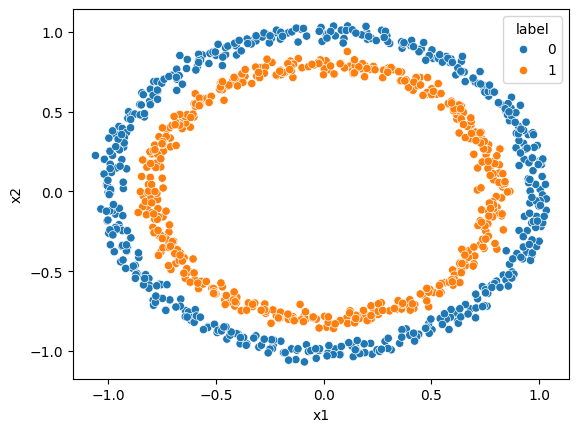

In [10]:
#Visualaze
import matplotlib.pyplot as plt
import seaborn as sns
sns.scatterplot(x="x1",y="x2",hue="label",data=circles)
plt.show()

In [11]:
#Check input and output shape
x.shape , y.shape

((1000, 2), (1000,))

In [12]:
#View for first example of features and labels
x_sample=x[0]
y_sample=y[0]
print(f"Sample input: {x_sample}")
print(f"Sample output: {y_sample}")

Sample input: [0.75424625 0.23148074]
Sample output: 1


In [13]:
print(f"There are {x.shape[0]} samples in the dataset")
print(f"The shape of x is: {x.shape}")
print(f"The shape of y is: {y.shape}")

There are 1000 samples in the dataset
The shape of x is: (1000, 2)
The shape of y is: (1000,)


In [14]:
x

array([[ 0.75424625,  0.23148074],
       [-0.75615888,  0.15325888],
       [-0.81539193,  0.17328203],
       ...,
       [-0.13690036, -0.81001183],
       [ 0.67036156, -0.76750154],
       [ 0.28105665,  0.96382443]])

In [15]:
import torch
x=torch.from_numpy(x).type(torch.float)
y=torch.from_numpy(y).type(torch.float)


In [16]:
type(x),x.dtype,y.dtype

(torch.Tensor, torch.float32, torch.float32)

In [17]:
#Split data into training and testing sets

In [18]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [19]:
len(x_train),len(x_test),len(y_train),len(y_test)

(800, 200, 800, 200)

In [20]:
#For builing a model

In [21]:
#Inport torch and nn
import torch
from torch import nn

In [22]:
#Set up device agnostic code
device='cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [23]:
#Construct a model that subclasses nn.module

In [24]:
x_train.shape

torch.Size([800, 2])

In [25]:
#Construct a model that subclasses nn.module
class circleModel(nn.Module):
  def __init__(self):
    super().__init__()
    #Create 2 nn.linear layer capable of handling the shapes of the data
    self.layer_1=nn.Linear(in_features=2,out_features=5)
    self.layer_2=nn.Linear(in_features=5,out_features=1)
  def forward(self,x):
    return self.layer_2(self.layer_1(x))      #x->layer_1->layer_2

In [26]:
#Instantiate an instance of our model class and send it to target device
model_0=circleModel().to(device)
model_0

circleModel(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)

In [27]:
next(model_0.parameters()).device

device(type='cuda', index=0)

In [28]:
#We can build the model even using nn.Sequential
model_1=nn.Sequential(
    nn.Linear(in_features=2,out_features=5),
    nn.Linear(in_features=5,out_features=1)
).to(device)

In [29]:
#In fact we can write in the class itself

In [30]:
class toyclass(nn.Module):
  def __init__(self):
    super().__init__()
    self.layers=nn.Sequential(
        nn.Linear(in_features=2,out_features=5),
        nn.Linear(in_features=5,out_features=1)

    )
  def forward(self,x):
    return self.layers(x)

In [31]:
model_2=toyclass().to(device)

In [32]:
model_1.state_dict()

OrderedDict([('0.weight',
              tensor([[-0.4411, -0.0150],
                      [ 0.3373, -0.5460],
                      [ 0.1099, -0.1027],
                      [-0.5562,  0.2844],
                      [ 0.5070,  0.5946]], device='cuda:0')),
             ('0.bias',
              tensor([ 0.4024, -0.2862,  0.5683,  0.0347,  0.6284], device='cuda:0')),
             ('1.weight',
              tensor([[ 0.3212,  0.3067,  0.3392,  0.4424, -0.0849]], device='cuda:0')),
             ('1.bias', tensor([-0.1366], device='cuda:0'))])

In [33]:
list(model_0.state_dict())

['layer_1.weight', 'layer_1.bias', 'layer_2.weight', 'layer_2.bias']

In [34]:
list

list

In [35]:
model_2

toyclass(
  (layers): Sequential(
    (0): Linear(in_features=2, out_features=5, bias=True)
    (1): Linear(in_features=5, out_features=1, bias=True)
  )
)

In [36]:
#Make some predictions

In [37]:
with torch.inference_mode():
  untrained_preds=model_1(x_test.to(device))
print(f"Length of predictions: {len(untrained_preds)}")
print(f"Shape of predictions: {untrained_preds.shape}")

Length of predictions: 200
Shape of predictions: torch.Size([200, 1])


In [38]:
print(f"Predictions on first 10 samples\n: {untrained_preds[:10]}")
print(f"Actual labels on first 10 samples\n: {y_test[:10]}")

Predictions on first 10 samples
: tensor([[ 0.0785],
        [-0.0714],
        [ 0.3049],
        [ 0.0150],
        [ 0.0409],
        [-0.0485],
        [-0.2612],
        [-0.2565],
        [ 0.3157],
        [-0.0844]], device='cuda:0')
Actual labels on first 10 samples
: tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


In [39]:
#Setup loss fn
loss_fn=nn.BCEWithLogitsLoss() #This has sigmoid activation fn built in
optimizer=torch.optim.SGD(params=model_1.parameters(),lr=0.1)

In [40]:
#Set up accuracy fn
def accuracy(y_true,y_pred):
  correct=torch.eq(y_true,y_pred).sum().item()
  acc=(correct/len(y_pred))*100
  return acc

In [41]:
#View the first 5 outputs of forward pass on test data

In [42]:
model_1.eval()
with torch.inference_mode():
  y_logits=model_1(x_test.to(device))[:5]
y_logits

tensor([[ 0.0785],
        [-0.0714],
        [ 0.3049],
        [ 0.0150],
        [ 0.0409]], device='cuda:0')

In [43]:
y_test[:5]

tensor([1., 0., 1., 0., 1.])

In [44]:
#We want in the same format of y_logits like y_test

In [45]:
#Use sigmoid activation function on our model logits to turn them into prediction probabities
y_pred_probs=torch.sigmoid(y_logits)
y_pred_probs

tensor([[0.5196],
        [0.4822],
        [0.5756],
        [0.5037],
        [0.5102]], device='cuda:0')

In [46]:
#Find the predicted lables
torch.round(y_pred_probs)

tensor([[1.],
        [0.],
        [1.],
        [1.],
        [1.]], device='cuda:0')

In [47]:
#In full
with torch.inference_mode():
  y_preds_lables=torch.round(torch.sigmoid(model_1(x_test.to(device))[:5]))
y_preds_lables

tensor([[1.],
        [0.],
        [1.],
        [1.],
        [1.]], device='cuda:0')

In [48]:
y_preds=torch.round(y_pred_probs)

In [49]:
#Chech eq:
print(torch.eq(y_preds.squeeze(),y_preds_lables.squeeze()))

tensor([True, True, True, True, True], device='cuda:0')


In [50]:
#Builing training and testing loop
torch.manual_seed(42)
torch.cuda.manual_seed(42)
epochs=100
#Put data into target device
x_train,y_train=x_train.to(device),y_train.to(device)
x_test,y_test=x_test.to(device),y_test.to(device)

In [51]:
for epoch in range(epochs):
  #Training
  model_1.train()
  #Forward Loss
  y_logits=model_1(x_train).squeeze()
  y_pred=torch.round(torch.sigmoid(y_logits))
  #Calculate the loss
  loss=loss_fn(y_logits,y_train)
  acc=accuracy(y_true=y_train,y_pred=y_pred)
  #Optimizer zero grad
  optimizer.zero_grad()
  #loss backward
  loss.backward()
  #optimizer step
  optimizer.step()

  #Testing
  model_1.eval()
  with torch.inference_mode():
    test_logits=model_1(x_test).squeeze()
    test_pred=torch.round(torch.sigmoid(test_logits))
    test_loss=loss_fn(test_logits,y_test)
    test_acc=accuracy(y_true=y_test,y_pred=test_pred)
  #Print what happened
  if epoch%10==0:
    print(f"Epoch: {epoch} | Loss: {loss:.5f} | Acc: {acc:.2f}% | Test Loss: {test_loss:.5f} | Test Acc: {test_acc}")

Epoch: 0 | Loss: 0.70013 | Acc: 51.00% | Test Loss: 0.69289 | Test Acc: 50.5
Epoch: 10 | Loss: 0.69844 | Acc: 50.62% | Test Loss: 0.69216 | Test Acc: 51.5
Epoch: 20 | Loss: 0.69724 | Acc: 50.00% | Test Loss: 0.69179 | Test Acc: 51.0
Epoch: 30 | Loss: 0.69634 | Acc: 50.00% | Test Loss: 0.69161 | Test Acc: 51.5
Epoch: 40 | Loss: 0.69565 | Acc: 50.00% | Test Loss: 0.69155 | Test Acc: 51.5
Epoch: 50 | Loss: 0.69512 | Acc: 50.00% | Test Loss: 0.69158 | Test Acc: 51.5
Epoch: 60 | Loss: 0.69469 | Acc: 49.88% | Test Loss: 0.69166 | Test Acc: 51.5
Epoch: 70 | Loss: 0.69436 | Acc: 50.25% | Test Loss: 0.69178 | Test Acc: 52.0
Epoch: 80 | Loss: 0.69410 | Acc: 50.62% | Test Loss: 0.69192 | Test Acc: 51.5
Epoch: 90 | Loss: 0.69388 | Acc: 50.50% | Test Loss: 0.69207 | Test Acc: 50.5


In [52]:
#The above looks like model is not learning any thing
#We now import helper functions from the github
import requests
from pathlib import Path
if Path("helper_functions.py").is_file():
  print("File already exists Skip downloading ")
else:
  print("Downloading helper functions")
  request=requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/refs/heads/main/helper_functions.py")
  with open('helper_functions.py','wb') as f:
    f.write(request.content)


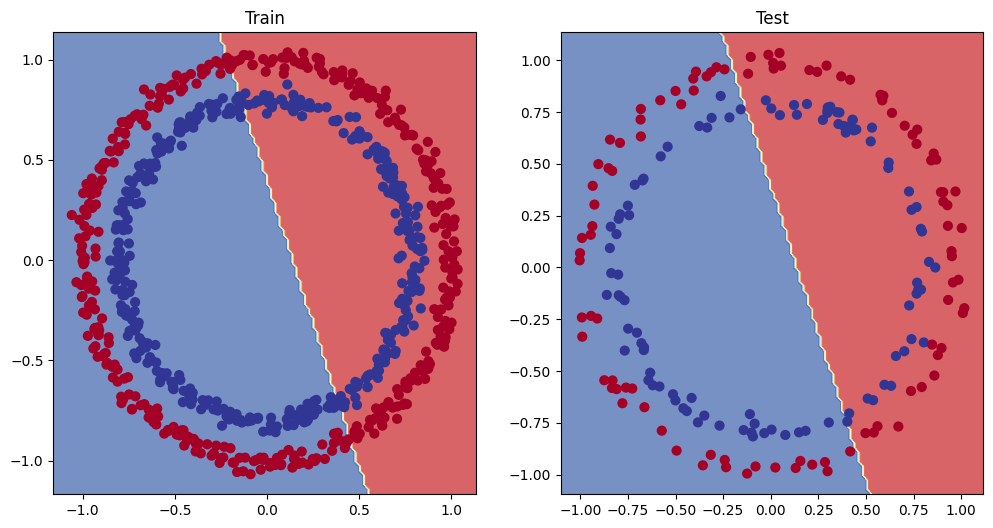

In [53]:
from helper_functions import plot_decision_boundary
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title('Train')
plot_decision_boundary(model_1,x_train,y_train)
plt.subplot(1,2,2)
plt.title('Test')
plot_decision_boundary(model_1,x_test,y_test)

In [54]:
#Creating new model:

In [55]:
class CircleModelv2(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer1=nn.Linear(in_features=2,out_features=10)
    self.layer2=nn.Linear(in_features=10,out_features=10)
    self.layer3=nn.Linear(in_features=10,out_features=1)
  def forward(self,x):
    #Can do in two ways
    # z=self.layer_1(x)
    # z=self.layer_2(z)
    # z=self.layer_3(z)
    return self.layer3(self.layer2(self.layer1(x)))

In [56]:
model_4=CircleModelv2().to(device)

In [57]:
loss_fn=nn.BCEWithLogitsLoss()
optimizer=torch.optim.SGD(params=model_4.parameters())

In [58]:
#Setup testing and trainig loop

In [59]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
epochs=1000
#Put Data in target device
x_train,y_train=x_train.to(device),y_train.to(device)
x_test,y_test=x_test.to(device),y_test.to(device)
for epoch in range(epochs):
  model_4.train()
  #Forward Pass
  y_logits=model_4(x_train).squeeze()
  y_pred=torch.round(torch.sigmoid(y_logits)) #Logits->Prediction Probabilitis

  #Calculate Loss
  loss=loss_fn(y_logits,y_train)
  acc=accuracy(y_true=y_train,y_pred=y_pred)
  #Optimizer Zero grad
  optimizer.zero_grad()

  loss.backward()

  optimizer.step()

  #Test
  model_4.eval()
  with torch.inference_mode():
    test_logits=model_4(x_test).squeeze()
    test_pred=torch.round(torch.sigmoid(test_logits))
    test_loss=loss_fn(test_logits,y_test)
    test_acc=accuracy(y_true=y_test,y_pred=test_pred)
  #Print whats happending
  if epoch%100==0:
    print(f"Epoch: {epoch} | Loss: {loss:.5f} | Acc: {acc:.2f}% | Test Loss: {test_loss:.5f} | Test Acc: {test_acc}")

Epoch: 0 | Loss: 0.69396 | Acc: 50.88% | Test Loss: 0.69261 | Test Acc: 51.0
Epoch: 100 | Loss: 0.69392 | Acc: 50.50% | Test Loss: 0.69261 | Test Acc: 51.0
Epoch: 200 | Loss: 0.69389 | Acc: 50.62% | Test Loss: 0.69262 | Test Acc: 50.5
Epoch: 300 | Loss: 0.69386 | Acc: 50.62% | Test Loss: 0.69263 | Test Acc: 50.5
Epoch: 400 | Loss: 0.69383 | Acc: 50.62% | Test Loss: 0.69263 | Test Acc: 51.0
Epoch: 500 | Loss: 0.69381 | Acc: 50.75% | Test Loss: 0.69264 | Test Acc: 50.5
Epoch: 600 | Loss: 0.69378 | Acc: 50.62% | Test Loss: 0.69265 | Test Acc: 51.0
Epoch: 700 | Loss: 0.69376 | Acc: 50.25% | Test Loss: 0.69266 | Test Acc: 51.0
Epoch: 800 | Loss: 0.69373 | Acc: 50.00% | Test Loss: 0.69267 | Test Acc: 50.5
Epoch: 900 | Loss: 0.69371 | Acc: 49.88% | Test Loss: 0.69268 | Test Acc: 50.5


In [60]:
#Creating a st.line dataset to see if out model is learning anything
weight=0.7
bias=0.3
x_reg=torch.arange(0,1,0.01).unsqueeze(dim=1)
y_reg=weight*x_reg+bias
x_reg[:5],y_reg[:5]

(tensor([[0.0000],
         [0.0100],
         [0.0200],
         [0.0300],
         [0.0400]]),
 tensor([[0.3000],
         [0.3070],
         [0.3140],
         [0.3210],
         [0.3280]]))

In [61]:
#Create Train and test spilits
train_split=int(0.8*len(x_reg))
x_train_regression,y_train_regression=x_reg[:train_split],y_reg[:train_split]
x_test_regression,y_test_regression=x_reg[train_split:],y_reg[train_split:]

In [62]:
len(x_train_regression),len(y_train_regression),len(x_test_regression),len(y_test_regression)

(80, 80, 20, 20)

In [63]:
from helper_functions import plot_predictions

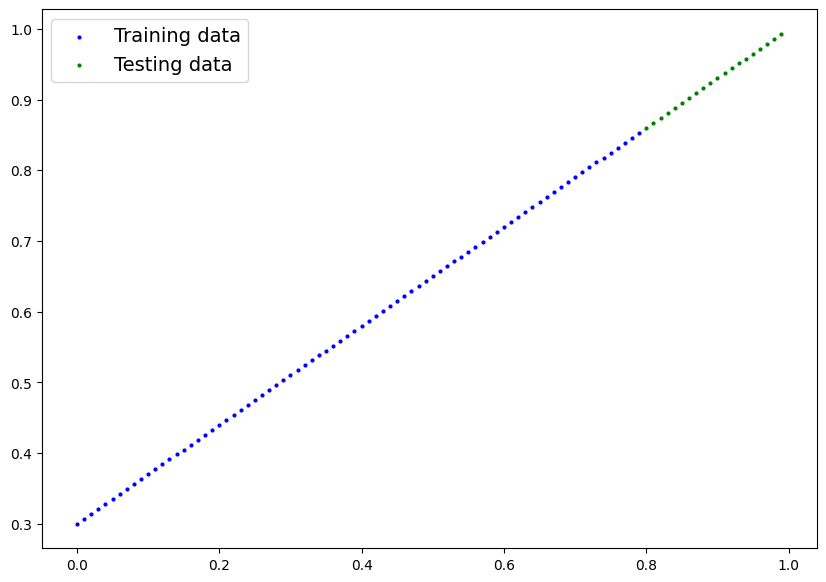

In [64]:
plot_predictions(train_data=x_train_regression,train_labels=y_train_regression,test_data=x_test_regression,test_labels=y_test_regression,predictions=None)

In [65]:
model_4

CircleModelv2(
  (layer1): Linear(in_features=2, out_features=10, bias=True)
  (layer2): Linear(in_features=10, out_features=10, bias=True)
  (layer3): Linear(in_features=10, out_features=1, bias=True)
)

In [66]:
#Adjusting our model_4 to fit a straight line

In [67]:
model_3=nn.Sequential(
    nn.Linear(in_features=1,out_features=10),
    nn.Linear(in_features=10,out_features=10),
    nn.Linear(in_features=10,out_features=1)
).to(device)

In [68]:
#Loss and optimizer

In [69]:
loss_fn=nn.L1Loss()
optimizer=torch.optim.SGD(params=model_3.parameters(),lr=0.01)

In [70]:
#Train and testing model
torch.manual_seed(42)
torch.cuda.manual_seed(42)
x_train_regression,y_train_regression=x_train_regression.to(device),y_train_regression.to(device)
x_test_regression,y_test_regression=x_test_regression.to(device),y_test_regression.to(device)

In [71]:
epochs=1000
for epoch in range(epochs):
  model_3.train()
  y_pred=model_3(x_train_regression)
  loss=loss_fn(y_pred,y_train_regression)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model_3.eval()
  with torch.inference_mode():
    test_pred=model_3(x_test_regression)
    test_loss=loss_fn(test_pred,y_test_regression)
  if epoch%100==0:
    print(f"Epoch {epoch} | Loss {loss} | Test Loss {test_loss}")

Epoch 0 | Loss 0.7598585486412048 | Test Loss 0.9110288619995117
Epoch 100 | Loss 0.028579557314515114 | Test Loss 0.0008127153269015253
Epoch 200 | Loss 0.02532542683184147 | Test Loss 0.002092161914333701
Epoch 300 | Loss 0.021374789997935295 | Test Loss 0.003051024628803134
Epoch 400 | Loss 0.01964489556849003 | Test Loss 0.003407812211662531
Epoch 500 | Loss 0.019402241334319115 | Test Loss 0.0038726211059838533
Epoch 600 | Loss 0.01903248392045498 | Test Loss 0.0037892551627010107
Epoch 700 | Loss 0.01878296583890915 | Test Loss 0.0038135319482535124
Epoch 800 | Loss 0.01839747093617916 | Test Loss 0.003287562867626548
Epoch 900 | Loss 0.017980346456170082 | Test Loss 0.0036039561964571476


In [72]:
#That means the model is actally learning something

In [73]:
#Evaluating our model predictions on st. line data

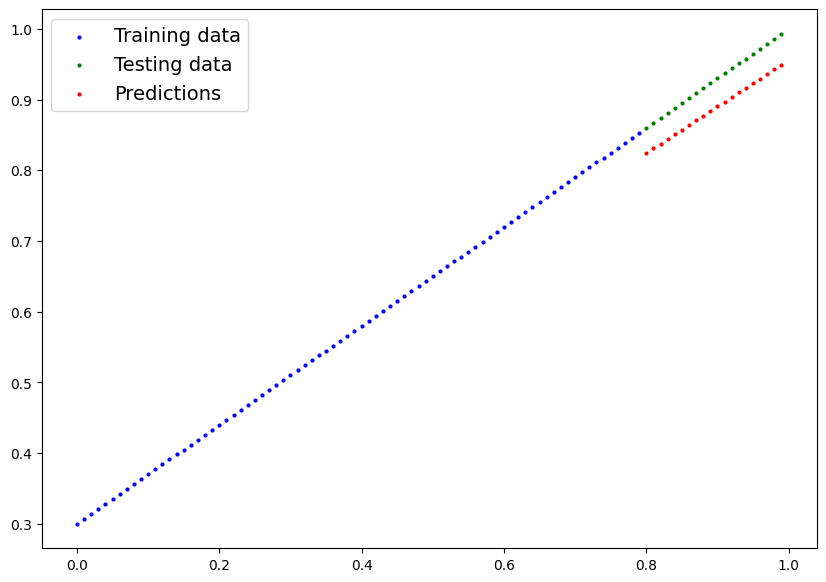

In [74]:
model_3.eval()
with torch.inference_mode():
  y_preds=model_3(x_test_regression)
plot_predictions(train_data=x_train_regression.cpu(),train_labels=y_train_regression.cpu(),test_data=x_test_regression.cpu(),test_labels=y_test_regression.cpu(),predictions=y_preds.cpu())

In [75]:
#The missing piece : Non Linearity

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_circles

In [77]:
n_samples=1000
x,y=make_circles(n_samples,noise=0.03,random_state=42)

[]

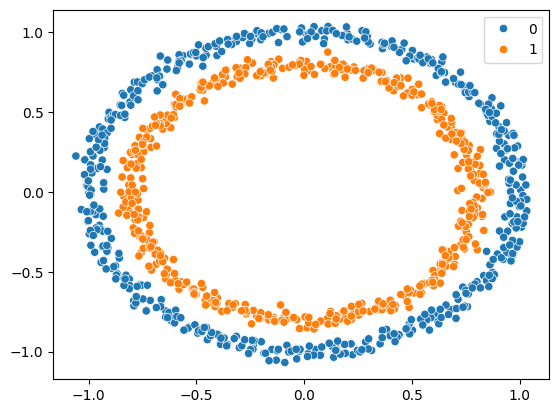

In [78]:
sns.scatterplot(x=x[:,0],y=x[:,1],hue=y)
plt.plot()

In [79]:
#Convert data to tensors
import torch
from sklearn.model_selection import train_test_split
x=torch.from_numpy(x).type(torch.float)
y=torch.from_numpy(y).type(torch.float)

In [80]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [81]:
x[:5],y[:5]

(tensor([[ 0.7542,  0.2315],
         [-0.7562,  0.1533],
         [-0.8154,  0.1733],
         [-0.3937,  0.6929],
         [ 0.4422, -0.8967]]),
 tensor([1., 1., 1., 1., 0.]))

In [82]:
#Building model with non linearity linear-->st.line    non linear--->non st lines

In [83]:
from torch import nn
class CicleModelv3(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer_1=nn.Linear(in_features=2,out_features=10)
    self.layer_2=nn.Linear(in_features=10,out_features=10)
    self.layer_3=nn.Linear(in_features=10,out_features=1)
    self.relu=nn.ReLU()
  def forward(self,x):
    return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))


In [84]:
model_5=CicleModelv3().to(device)

In [85]:
model_5

CicleModelv3(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)

In [86]:
#Set up loss and optimizer
loss_fn=nn.BCEWithLogitsLoss()
optimizer=torch.optim.SGD(params=model_5.parameters(),lr=0.1)

In [87]:
#Training and testing
torch.manual_seed(42)
torch.cuda.manual_seed(42)
x_train,y_train=x_train.to(device),y_train.to(device)
x_test,y_test=x_test.to(device),y_test.to(device)
for epoch in range(epochs):
  model_5.train()
  y_logits=model_5(x_train).squeeze()
  y_pred=torch.round(torch.sigmoid(y_logits))
  loss=loss_fn(y_logits,y_train)
  acc=accuracy(y_true=y_train,y_pred=y_pred)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model_5.eval()
  with torch.inference_mode():
    test_logits=model_5(x_test).squeeze()
    test_pred=torch.round(torch.sigmoid(test_logits))
    test_loss=loss_fn(test_logits,y_test)
    test_acc=accuracy(y_true=y_test,y_pred=test_pred)
  if epoch%100==0:
    print(f"Epoch: {epoch} | Loss: {loss:.5f} | Acc: {acc:.2f}% | Test Loss: {test_loss:.5f} | Test Acc: {test_acc}")

Epoch: 0 | Loss: 0.69295 | Acc: 50.00% | Test Loss: 0.69319 | Test Acc: 50.0
Epoch: 100 | Loss: 0.69115 | Acc: 52.88% | Test Loss: 0.69102 | Test Acc: 52.5
Epoch: 200 | Loss: 0.68977 | Acc: 53.37% | Test Loss: 0.68940 | Test Acc: 55.00000000000001
Epoch: 300 | Loss: 0.68795 | Acc: 53.00% | Test Loss: 0.68723 | Test Acc: 56.00000000000001
Epoch: 400 | Loss: 0.68517 | Acc: 52.75% | Test Loss: 0.68411 | Test Acc: 56.49999999999999
Epoch: 500 | Loss: 0.68102 | Acc: 52.75% | Test Loss: 0.67941 | Test Acc: 56.49999999999999
Epoch: 600 | Loss: 0.67515 | Acc: 54.50% | Test Loss: 0.67285 | Test Acc: 56.00000000000001
Epoch: 700 | Loss: 0.66659 | Acc: 58.38% | Test Loss: 0.66322 | Test Acc: 59.0
Epoch: 800 | Loss: 0.65160 | Acc: 64.00% | Test Loss: 0.64757 | Test Acc: 67.5
Epoch: 900 | Loss: 0.62362 | Acc: 74.00% | Test Loss: 0.62145 | Test Acc: 79.0


In [88]:
model_5.eval()
with torch.inference_mode():
  y_logits=model_5(x_test).squeeze()
  y_pred=torch.round(torch.sigmoid(y_logits))
y_pred[:10],y_test[:10]

(tensor([1., 0., 1., 0., 0., 1., 0., 0., 1., 0.], device='cuda:0'),
 tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.], device='cuda:0'))

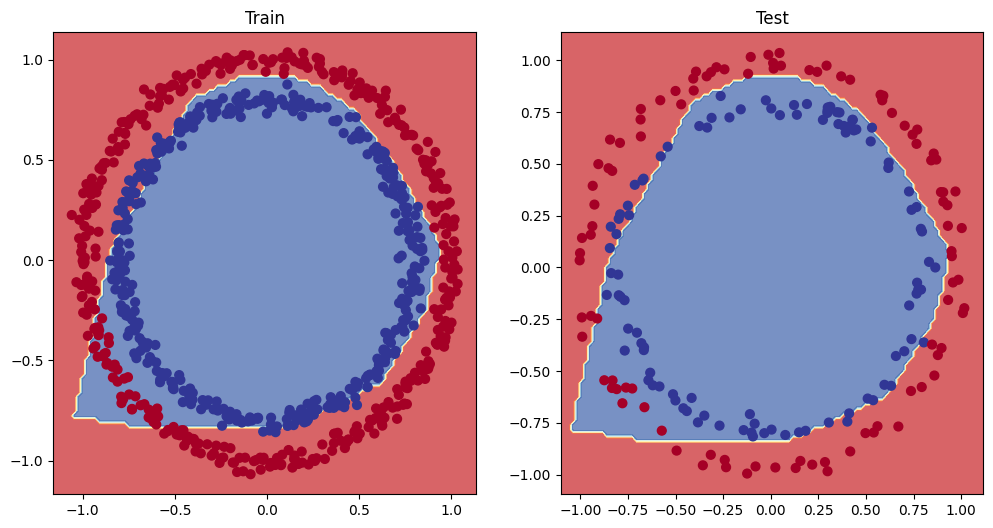

In [89]:
#Plot decision boundary
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title('Train')
plot_decision_boundary(model_5,x_train,y_train)
plt.subplot(1,2,2)
plt.title('Test')
plot_decision_boundary(model_5,x_test,y_test)



In [90]:
#Replicating non linear

In [91]:
A=torch.arange(-10,10,1,dtype=torch.float32)

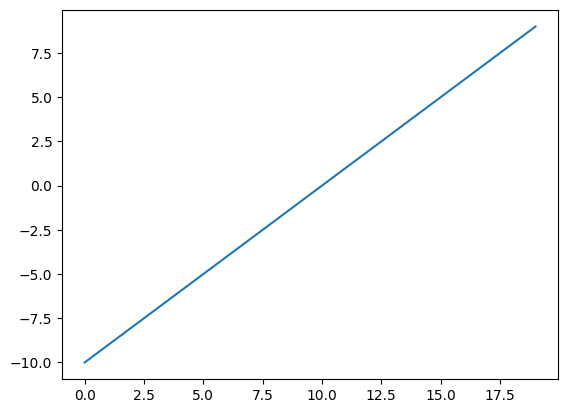

In [92]:
plt.plot(A)

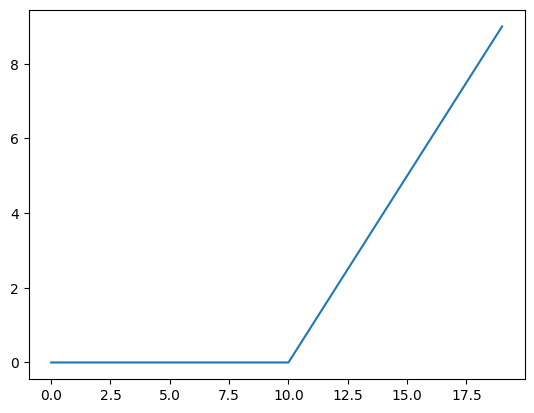

In [93]:
plt.plot(torch.relu(A))

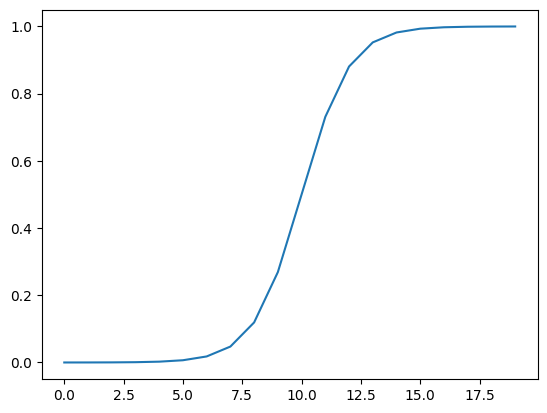

In [94]:
plt.plot(torch.sigmoid(A))

In [95]:
#Everything together with a multiclass classification problem

In [96]:
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

In [97]:
from sklearn.model_selection import train_test_split

In [98]:
x,y=make_blobs(n_samples=1000,n_features=2,centers=4,cluster_std=1.5,random_state=42)

In [99]:
#Turn data into tensors
x=torch.from_numpy(x).type(torch.float)
y=torch.from_numpy(y).type(torch.LongTensor)

In [100]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

<Axes: xlabel='None', ylabel='None'>

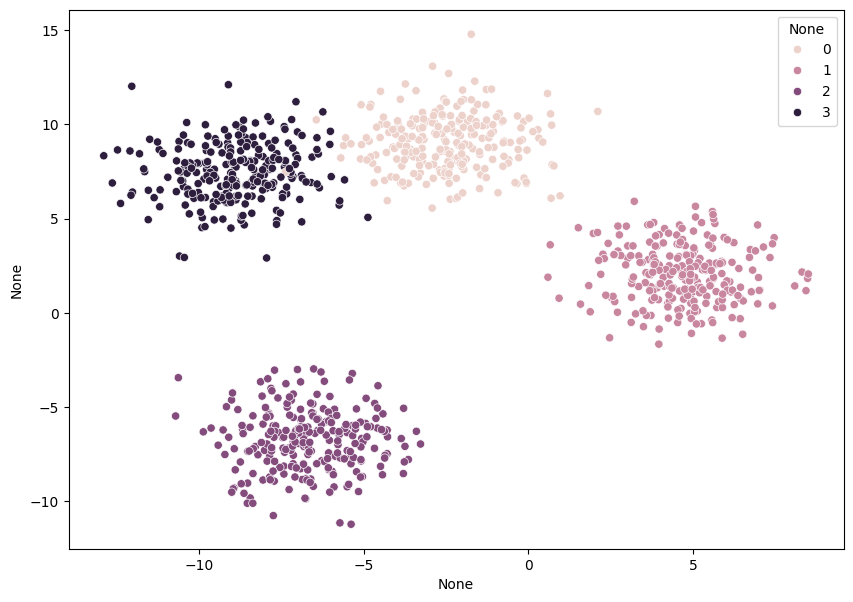

In [101]:
#Plot data
#Scatter plot
import seaborn as sns
plt.figure(figsize=(10,7))
sns.scatterplot(x=x[:,0],y=x[:,1],hue=y)

In [102]:
#Building a multiclass classification model

In [103]:
#Create device agnositc code

In [104]:
device='cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [105]:
x_train,y_train=x_train.to(device),y_train.to(device)
x_test,y_test=x_test.to(device),y_test.to(device)

In [106]:
class BlobModel(nn.Module):
  def __init__(self,input_features,output_features,hidden_units=8):
    super().__init__()
    self.linear_layer_stack=nn.Sequential(
        nn.Linear(in_features=input_features,out_features=hidden_units),
        nn.ReLU(),
        nn.Linear(in_features=hidden_units,out_features=hidden_units),
        nn.ReLU(),
        nn.Linear(in_features=hidden_units,out_features=output_features)
    )
  def forward(self,x):
      return self.linear_layer_stack(x)

In [107]:
model_6=BlobModel(input_features=2,output_features=4).to(device)

In [108]:
model_6

BlobModel(
  (linear_layer_stack): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=4, bias=True)
  )
)

In [109]:
x_train.shape

torch.Size([800, 2])

In [110]:
y.unique()

tensor([0, 1, 2, 3])

In [111]:
#Create loss function and optimizer
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD(params=model_6.parameters(),lr=0.1)

In [112]:
model_6.eval()
with torch.inference_mode():
  y_pr=model_6(x_test)


In [113]:
y_pr[:3]

tensor([[-0.7646, -0.7412, -1.5777, -1.1376],
        [-0.0973, -0.9431, -0.5963, -0.1371],
        [ 0.2528, -0.2379,  0.1882, -0.0066]], device='cuda:0')

In [114]:
#Now we want y_pr in the form of y_test

In [115]:
y_test[:5]

tensor([1, 3, 2, 1, 0], device='cuda:0')

In [116]:
#Build a training loop

In [117]:
#Convert logits output to prediction probabilities
y_pred_prob=torch.softmax(y_pr,dim=1)

In [118]:
y_pred_prob[:5]

tensor([[0.3169, 0.3244, 0.1405, 0.2182],
        [0.3336, 0.1432, 0.2026, 0.3206],
        [0.3011, 0.1843, 0.2823, 0.2323],
        [0.3078, 0.2766, 0.1836, 0.2320],
        [0.3719, 0.1286, 0.1532, 0.3463]], device='cuda:0')

In [119]:
#To get the actual prediction we use arg max
torch.argmax(y_pred_prob[0])

tensor(1, device='cuda:0')

In [120]:
#Convert our models prediction probabilities to prediction labels
y_preds=torch.argmax(y_pred_prob,dim=1)
y_preds

tensor([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 3, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
        1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 1, 0, 1, 0, 0, 0,
        0, 0, 0, 0, 3, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        1, 0, 0, 0, 0, 1, 0, 1], device='cuda:0')

In [121]:
#Training and Testing Loop
torch.manual_seed(42)
torch.cuda.manual_seed(42)
epochs=100
x_train,y_train=x_train.to(device),y_train.to(device)
x_test,y_test=x_test.to(device),y_test.to(device)
for epoch in range(epochs):
  model_6.train()
  y_logits=model_6(x_train)
  y_pred=torch.softmax(y_logits,dim=1).argmax(dim=1)
  loss=loss_fn(y_logits,y_train)
  acc=accuracy(y_true=y_train,y_pred=y_pred)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model_6.eval()
  with torch.inference_mode():
    test_logits=model_6(x_test)
    test_pred=torch.softmax(test_logits,dim=1).argmax(dim=1)
    test_loss=loss_fn(test_logits,y_test)
    test_acc=accuracy(y_true=y_test,y_pred=test_pred)
  if epoch%10==0:
    print(f"Epoch: {epoch} | Loss: {loss:.5f} | Acc: {acc:.2f}% | Test Loss: {test_loss:.5f} | Test Acc: {test_acc}")

Epoch: 0 | Loss: 1.15883 | Acc: 40.38% | Test Loss: 1.07554 | Test Acc: 48.0
Epoch: 10 | Loss: 0.64476 | Acc: 96.75% | Test Loss: 0.66069 | Test Acc: 97.5
Epoch: 20 | Loss: 0.42535 | Acc: 98.50% | Test Loss: 0.43074 | Test Acc: 100.0
Epoch: 30 | Loss: 0.25294 | Acc: 99.12% | Test Loss: 0.24508 | Test Acc: 99.5
Epoch: 40 | Loss: 0.11232 | Acc: 99.25% | Test Loss: 0.10229 | Test Acc: 99.5
Epoch: 50 | Loss: 0.06627 | Acc: 99.25% | Test Loss: 0.05848 | Test Acc: 99.5
Epoch: 60 | Loss: 0.05068 | Acc: 99.25% | Test Loss: 0.04293 | Test Acc: 99.5
Epoch: 70 | Loss: 0.04300 | Acc: 99.25% | Test Loss: 0.03491 | Test Acc: 99.5
Epoch: 80 | Loss: 0.03836 | Acc: 99.25% | Test Loss: 0.02988 | Test Acc: 99.5
Epoch: 90 | Loss: 0.03525 | Acc: 99.25% | Test Loss: 0.02663 | Test Acc: 99.5


In [122]:
#Plot decision boundary
model_6.eval()
with torch.inference_mode():
  y_logits=model_6(x_test)
  y_pred=torch.softmax(y_logits,dim=1).argmax(dim=1)
y_pred[:5]

tensor([1, 3, 2, 1, 0], device='cuda:0')

In [123]:
y_test[:5]

tensor([1, 3, 2, 1, 0], device='cuda:0')

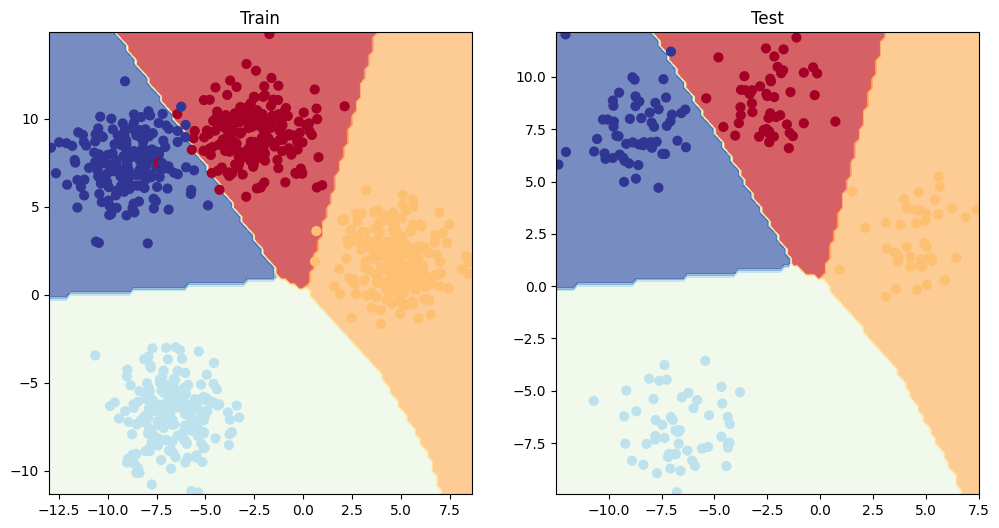

In [124]:
#Visualize
import torch
import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title('Train')
plot_decision_boundary(model_6,x_train,y_train)
plt.subplot(1,2,2)
plt.title('Test')
plot_decision_boundary(model_6,x_test,y_test)

In [125]:
#Metrics
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 30.1 MB/s eta 0:00:00


In [126]:
from torchmetrics import Accuracy
torchmetric_accuracy=Accuracy (task="multiclass",
    num_classes=4).to(device)
torchmetric_accuracy(y_pred,y_test)

tensor(0.9950, device='cuda:0')